<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook11_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Cell 1: setup and the new target
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y_grade = train["G3"]
y = (y_grade < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # keeps the at-risk share in every fold
print("Training students:", len(y))
print("At risk (G3 < 10):", y.sum(), f"({y.mean():.1%})")
print("Not at risk      :", (1 - y).sum(), f"({1 - y.mean():.1%})")

Training students: 285
At risk (G3 < 10): 73 (25.6%)
Not at risk      : 212 (74.4%)


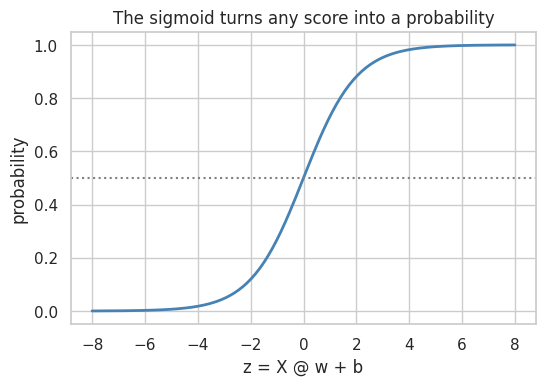

From scratch :  w = [-4.768]  b = -3.583
scikit-learn :  w = [-5.534]  b = [-4.156]


In [3]:
# Cell 2: the sigmoid, and logistic regression from scratch (one feature: G2)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

zs = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3.8))
plt.plot(zs, sigmoid(zs), color="steelblue", linewidth=2)
plt.axhline(0.5, color="gray", linestyle=":")
plt.xlabel("z = X @ w + b"); plt.ylabel("probability")
plt.title("The sigmoid turns any score into a probability")
plt.savefig("sigmoid.png", dpi=150, bbox_inches="tight")
plt.show()

x = ((train["G2"] - train["G2"].mean()) / train["G2"].std()).values.reshape(-1, 1)
yy = y.values
w, b = np.zeros(1), 0.0
for _ in range(3000):
    p = sigmoid(x @ w + b)
    w -= 0.1 * (x.T @ (p - yy)) / len(yy)      # same shape as Day 11, but with (p - y)
    b -= 0.1 * (p - yy).mean()

sk = LogisticRegression(C=1e6, max_iter=5000).fit(x, yy)     # almost no regularisation
print("From scratch :  w =", w.round(3), " b =", round(b, 3))
print("scikit-learn :  w =", sk.coef_[0].round(3), " b =", sk.intercept_.round(3))

In [4]:
# Cell 3: the "do nothing" baseline
dummy_pred = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_all, y, cv=skf)
print("Flag nobody  -> accuracy:", round(accuracy_score(y, dummy_pred), 3),
      "| recall:", recall_score(y, dummy_pred),
      "| students caught:", int(((dummy_pred == 1) & (y == 1)).sum()))
print("Accuracy looks respectable, yet this 'model' helps no one.")

Flag nobody  -> accuracy: 0.744 | recall: 0.0 | students caught: 0
Accuracy looks respectable, yet this 'model' helps no one.


In [5]:
# Cell 4: logistic regression, cross-validated probabilities for both feature sets
def make_lr(**kwargs):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, **kwargs))

proba = {}
for fname, X in feature_sets.items():
    proba[fname] = cross_val_predict(make_lr(), X, y, cv=skf, method="predict_proba")[:, 1]

def metrics_at(p, t=0.5):
    flag = (p >= t).astype(int)
    return {"flagged": int(flag.sum()),
            "accuracy": round(accuracy_score(y, flag), 3),
            "precision": round(precision_score(y, flag, zero_division=0), 3),
            "recall": round(recall_score(y, flag, zero_division=0), 3),
            "F1": round(f1_score(y, flag, zero_division=0), 3),
            "ROC AUC": round(roc_auc_score(y, p), 3),
            "PR AUC": round(average_precision_score(y, p), 3)}

results = pd.DataFrame({fname: metrics_at(p) for fname, p in proba.items()}).T
results

,flagged,accuracy,precision,recall,F1,ROC AUC,PR AUC
early (no G1/G2),45.0,0.740,0.489,0.301,0.373,0.662,0.412
all features,65.0,0.881,0.800,0.712,0.754,0.954,0.878


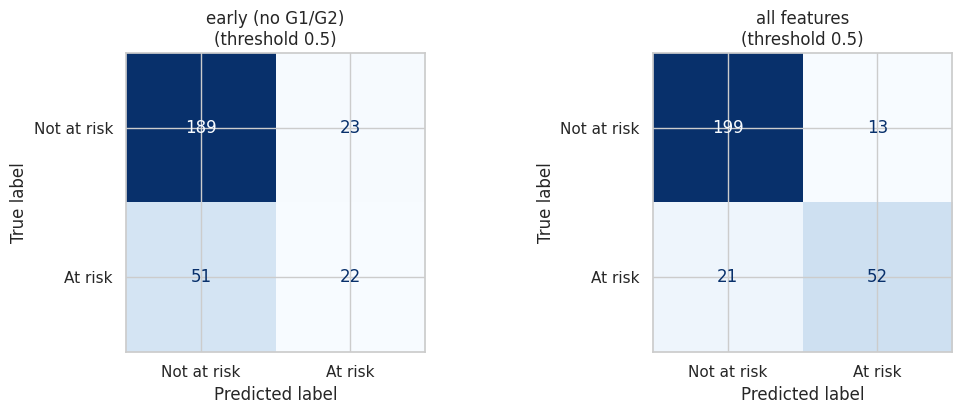

In [6]:
# Cell 5: confusion matrices at the default 0.5 threshold
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (fname, p) in zip(axes, proba.items()):
    ConfusionMatrixDisplay.from_predictions(y, (p >= 0.5).astype(int), ax=ax,
                                            display_labels=["Not at risk", "At risk"],
                                            cmap="Blues", colorbar=False)
    ax.set_title(f"{fname}\n(threshold 0.5)")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

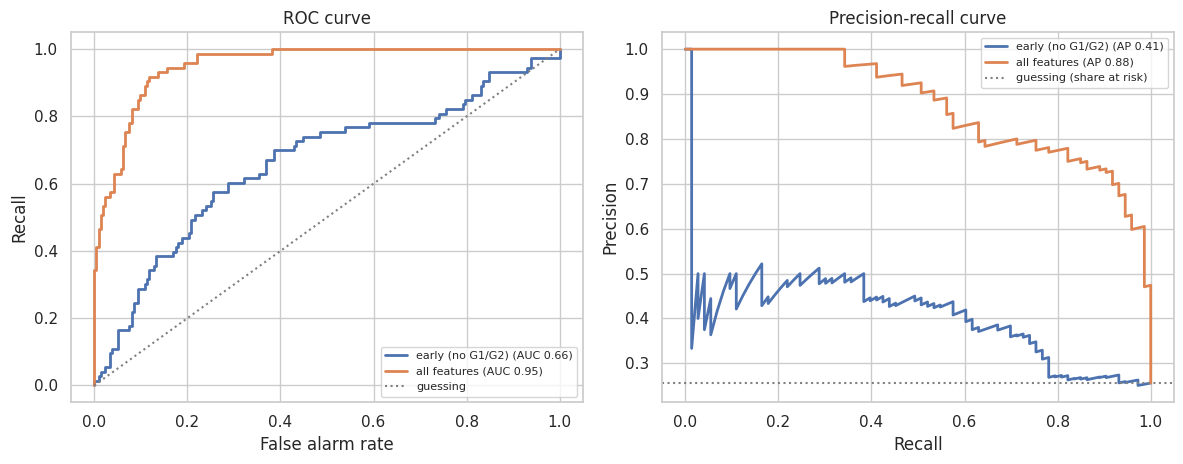

In [7]:
# Cell 6: ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for fname, p in proba.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{fname} (AUC {roc_auc_score(y, p):.2f})")
    pr, rc, _ = precision_recall_curve(y, p)
    axes[1].plot(rc, pr, linewidth=2, label=f"{fname} (AP {average_precision_score(y, p):.2f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle=":", label="guessing")
axes[0].set_xlabel("False alarm rate"); axes[0].set_ylabel("Recall"); axes[0].set_title("ROC curve")
axes[1].axhline(y.mean(), color="gray", linestyle=":", label="guessing (share at risk)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Cell 7: the threshold decides the trade-off
rows = []
for fname, p in proba.items():
    for t in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6]:
        flag = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, flag).ravel()
        rows.append({"features": fname, "threshold": t,
                     "flagged %": round(flag.mean() * 100, 1),
                     "caught": tp, "missed": fn, "false alarms": fp,
                     "precision": round(precision_score(y, flag, zero_division=0), 2),
                     "recall": round(recall_score(y, flag), 2)})
threshold_table = pd.DataFrame(rows)
threshold_table

# the highest threshold that still catches at least 80% of at-risk students
print()
for fname, p in proba.items():
    ok = [t for t in np.linspace(0.01, 0.99, 99) if recall_score(y, (p >= t).astype(int)) >= 0.80]
    if ok:
        t = max(ok); flag = (p >= t).astype(int)
        print(f"{fname}: threshold {t:.2f} -> flags {flag.mean():.0%} of students, "
              f"precision {precision_score(y, flag):.2f}, recall {recall_score(y, flag):.2f}")
    else:
        print(f"{fname}: no threshold reaches 80% recall")


early (no G1/G2): threshold 0.05 -> flags 79% of students, precision 0.27, recall 0.82
all features: threshold 0.36 -> flags 27% of students, precision 0.78, recall 0.81


In [9]:
# Cell 8: class_weight="balanced" makes the model care more about the at-risk group
rows = {}
for fname, X in feature_sets.items():
    p_bal = cross_val_predict(make_lr(class_weight="balanced"), X, y, cv=skf, method="predict_proba")[:, 1]
    rows[f"{fname}, default"] = metrics_at(proba[fname])
    rows[f"{fname}, balanced"] = metrics_at(p_bal)
pd.DataFrame(rows).T

,flagged,accuracy,precision,recall,F1,ROC AUC,PR AUC
"early (no G1/G2), default",45.0,0.740,0.489,0.301,0.373,0.662,0.412
"early (no G1/G2), balanced",102.0,0.688,0.422,0.589,0.491,0.671,0.409
"all features, default",65.0,0.881,0.800,0.712,0.754,0.954,0.878
"all features, balanced",77.0,0.888,0.766,0.808,0.787,0.955,0.883


In [10]:
# Cell 9: tune C inside nested cross-validation (small C = strong regularisation)
grid = {"logisticregression__C": np.logspace(-3, 2, 20)}
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

rows = []
for fname, X in feature_sets.items():
    gs = GridSearchCV(make_lr(), grid, cv=skf, scoring="roc_auc", n_jobs=-1).fit(X, y)
    nested = cross_val_score(GridSearchCV(make_lr(), grid, cv=skf, scoring="roc_auc", n_jobs=-1),
                             X, y, cv=outer, scoring="roc_auc")
    default = cross_val_score(make_lr(), X, y, cv=outer, scoring="roc_auc")
    rows.append({"features": fname,
                 "best C": round(gs.best_params_["logisticregression__C"], 3),
                 "default AUC": round(default.mean(), 3),
                 "tuned AUC (nested, honest)": round(nested.mean(), 3)})
pd.DataFrame(rows)

,features,best C,default AUC,"tuned AUC (nested, honest)"
0,early (no G1/G2),0.070,0.672,0.672
1,all features,2.637,0.961,0.946


In [11]:
# Cell 10: classifier vs flagging from the Ridge grade prediction (Day 13 idea)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for fname, X in feature_sets.items():
    pred_grade = cross_val_predict(make_pipeline(StandardScaler(), Ridge(alpha=10)), X, y_grade, cv=kf)
    rows.append({"features": fname,
                 "AUC, Ridge predicted grade": round(roc_auc_score(y, -pred_grade), 3),
                 "AUC, logistic probability": round(roc_auc_score(y, proba[fname]), 3)})
pd.DataFrame(rows)

,features,"AUC, Ridge predicted grade","AUC, logistic probability"
0,early (no G1/G2),0.720,0.662
1,all features,0.968,0.954


Odds ratio per 1 standard deviation increase (above 1 = more at risk, below 1 = less):
goout            1.85
absences         1.80
schoolsup        1.63
failures         1.54
famsup           1.49
age              1.35
Mjob_services    0.66
Mjob_teacher     1.32


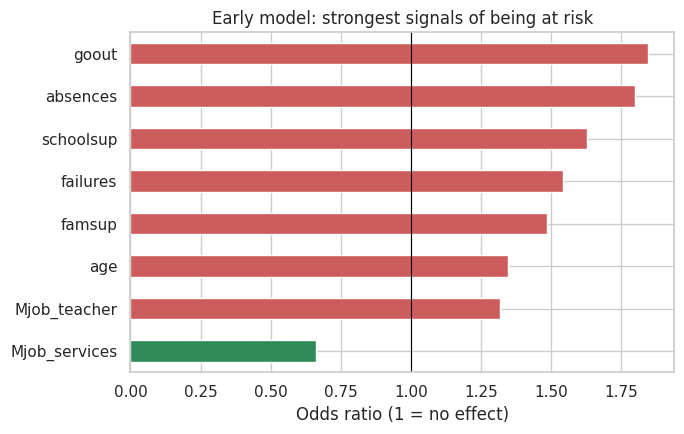


All-features model, odds ratio for G2: 0.02


In [12]:
# Cell 11: what drives risk? Odds ratios from the early model
model = make_lr().fit(X_early, y)
coef = pd.Series(model[-1].coef_[0], index=X_early.columns)
odds = np.exp(coef)
top = odds.reindex((odds - 1).abs().sort_values(ascending=False).index).head(8)

print("Odds ratio per 1 standard deviation increase (above 1 = more at risk, below 1 = less):")
print(top.round(2).to_string())

plt.figure(figsize=(7, 4.5))
top.sort_values().plot(kind="barh", color=np.where(top.sort_values() > 1, "indianred", "seagreen"))
plt.axvline(1, color="black", linewidth=0.8)
plt.xlabel("Odds ratio (1 = no effect)")
plt.title("Early model: strongest signals of being at risk")
plt.tight_layout()
plt.savefig("odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

model_all = make_lr().fit(X_all, y)
print("\nAll-features model, odds ratio for G2:",
      round(float(np.exp(model_all[-1].coef_[0][list(X_all.columns).index("G2")])), 2))

In [13]:
# Cell 12: save the results for the final report
results.to_csv("classification_results.csv")
threshold_table.to_csv("threshold_table.csv", index=False)
print("Saved classification_results.csv and threshold_table.csv")
print(results.to_string())

Saved classification_results.csv and threshold_table.csv
                  flagged  accuracy  precision  recall     F1  ROC AUC  PR AUC
early (no G1/G2)     45.0     0.740      0.489   0.301  0.373    0.662   0.412
all features         65.0     0.881      0.800   0.712  0.754    0.954   0.878
